In [5]:
!pip install scikit-learn

In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from sklearn.decomposition import PCA

In [7]:
Root = Path.cwd()

Features_Dir = (
    Root
    / "output"
    / "features"
)

Pca_Dir = (
    Root
    / "output"
    / "pca"
)

Samples_Dir = (
    Root
    / "output"
    / "samples"
)

Pca_Dir.mkdir(
    parents=True,
    exist_ok=True
)

Feature_Path = (
    Features_Dir
    / "sample_video_features.pt"
)

Sample_Tensor_Path = (
    Samples_Dir
    / "sample_video_tensor.pt"
)

print("Feature Path:", Feature_Path)
print("Sample Tensor Path:", Sample_Tensor_Path)
print("PCA Output:", Pca_Dir)

Feature Path: d:\project\Personal\Hadi\EchoJEPA\output\features\sample_video_features.pt
Sample Tensor Path: d:\project\Personal\Hadi\EchoJEPA\output\samples\sample_video_tensor.pt
PCA Output: d:\project\Personal\Hadi\EchoJEPA\output\pca


In [8]:
Saved_Features = torch.load(
    Feature_Path,
    map_location="cpu"
)

Patch_Features = Saved_Features[
    "patch_features"
]

print(
    "Patch Features Shape:",
    Patch_Features.shape
)

print(
    "Patch Features dtype:",
    Patch_Features.dtype
)

Patch Features Shape: torch.Size([1, 16, 14, 14, 1024])
Patch Features dtype: torch.float32


In [9]:
assert Patch_Features.shape == (
    1,
    16,
    14,
    14,
    1024
)

assert torch.isfinite(
    Patch_Features
).all()

print(
    "Patch Features validation passed."
)

Patch Features validation passed.


In [10]:
Patch_Features_Numpy = (
    Patch_Features
    .numpy()
)

print(
    "NumPy Shape:",
    Patch_Features_Numpy.shape
)

NumPy Shape: (1, 16, 14, 14, 1024)


In [11]:
PCA_Input = Patch_Features_Numpy.reshape(
    -1,
    1024
)

print(
    "PCA Input Shape:",
    PCA_Input.shape
)

PCA Input Shape: (3136, 1024)


In [12]:
PCA_Model = PCA(
    n_components=3
)

In [13]:
PCA_Features = PCA_Model.fit_transform(
    PCA_Input
)

print(
    "PCA Features Shape:",
    PCA_Features.shape
)

print(
    "Explained Variance Ratio:",
    PCA_Model.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    PCA_Model.explained_variance_ratio_.sum()
)

PCA Features Shape: (3136, 3)
Explained Variance Ratio: [0.22330654 0.07330427 0.05994104]
Total Explained Variance: 0.35655186


In [14]:
PCA_Video = PCA_Features.reshape(
    16,
    14,
    14,
    3
)

print(
    "PCA Video Shape:",
    PCA_Video.shape
)

PCA Video Shape: (16, 14, 14, 3)


In [15]:
PCA_Min = PCA_Video.min(
    axis=(0, 1, 2),
    keepdims=True
)

PCA_Max = PCA_Video.max(
    axis=(0, 1, 2),
    keepdims=True
)

PCA_Visualization = (
    PCA_Video - PCA_Min
) / (
    PCA_Max - PCA_Min + 1e-8
)

print(
    "Visualization Min:",
    PCA_Visualization.min()
)

print(
    "Visualization Max:",
    PCA_Visualization.max()
)

Visualization Min: 0.0
Visualization Max: 1.0


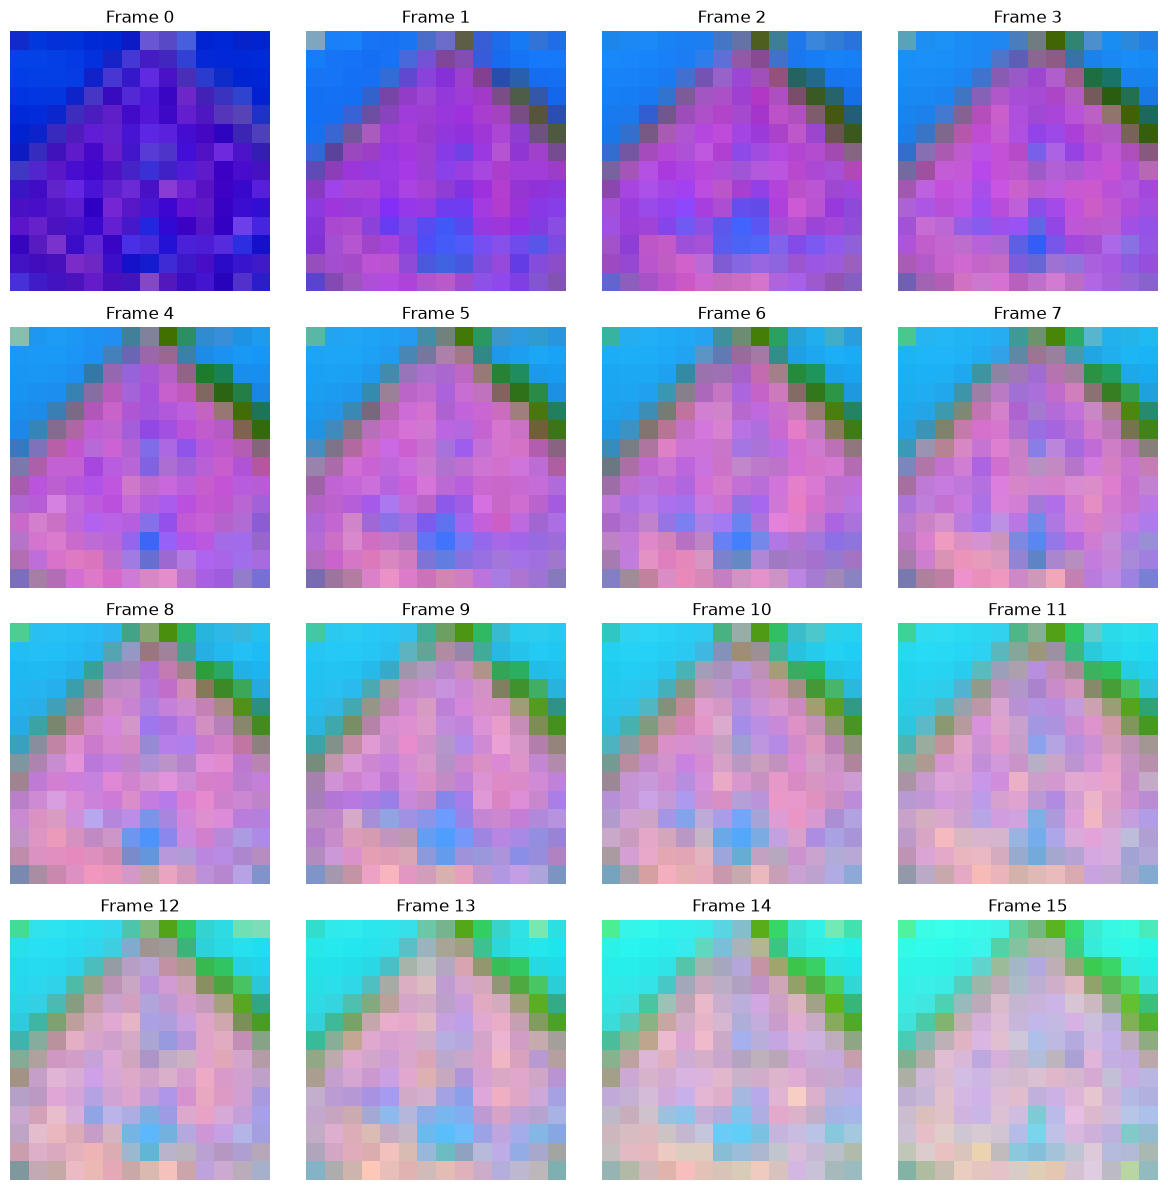

In [16]:
plt.figure(
    figsize=(12, 12)
)

for Frame_Index in range(16):

    plt.subplot(
        4,
        4,
        Frame_Index + 1
    )

    plt.imshow(
        PCA_Visualization[
            Frame_Index
        ]
    )

    plt.title(
        f"Frame {Frame_Index}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
PCA_Result_Path = (
    Pca_Dir
    / "pca_before_finetuning.pt"
)

torch.save(
    {
        "pca_features": torch.from_numpy(
            PCA_Features
        ),

        "pca_video": torch.from_numpy(
            PCA_Video
        ),

        "explained_variance_ratio": torch.from_numpy(
            PCA_Model.explained_variance_ratio_
        )
    },
    PCA_Result_Path
)

print(
    "PCA baseline saved:",
    PCA_Result_Path
)

PCA baseline saved: d:\project\Personal\Hadi\EchoJEPA\output\pca\pca_before_finetuning.pt


In [18]:
import joblib

PCA_Model_Path = (
    Pca_Dir
    / "pca_before_finetuning_model.joblib"
)

joblib.dump(
    PCA_Model,
    PCA_Model_Path
)

print(
    "PCA model saved:",
    PCA_Model_Path
)

PCA model saved: d:\project\Personal\Hadi\EchoJEPA\output\pca\pca_before_finetuning_model.joblib


In [19]:
Upsampled_PCA_Frames = []

for Frame_Index in range(16):

    Upsampled_Frame = cv2.resize(
        PCA_Visualization[Frame_Index],
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    Upsampled_PCA_Frames.append(
        Upsampled_Frame
    )

Upsampled_PCA_Frames = np.stack(
    Upsampled_PCA_Frames,
    axis=0
)

print(
    "Upsampled PCA Shape:",
    Upsampled_PCA_Frames.shape
)

Upsampled PCA Shape: (16, 224, 224, 3)


In [20]:
Sample_Video = torch.load(
    Sample_Tensor_Path,
    map_location="cpu"
)

print(
    "Sample Video Shape:",
    Sample_Video.shape
)

Sample Video Shape: torch.Size([1, 3, 16, 224, 224])


In [21]:
ImageNet_Mean = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(
    1, 3, 1, 1, 1
)

ImageNet_Std = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(
    1, 3, 1, 1, 1
)

Denormalized_Video = (
    Sample_Video * ImageNet_Std
) + ImageNet_Mean

Denormalized_Video = torch.clamp(
    Denormalized_Video,
    0.0,
    1.0
)

print(
    Denormalized_Video.min().item(),
    Denormalized_Video.max().item()
)

0.0 0.9960784912109375


In [22]:
Display_Video = (
    Denormalized_Video[0]
    .permute(
        1,
        2,
        3,
        0
    )
    .numpy()
)

print(
    "Display Video Shape:",
    Display_Video.shape
)

Display Video Shape: (16, 224, 224, 3)


In [23]:
Frame_Index = 0

Original_Frame = Display_Video[
    Frame_Index
]

PCA_Frame = Upsampled_PCA_Frames[
    Frame_Index
]

Alpha = 0.45

Overlay_Frame = (
    (1 - Alpha) * Original_Frame
    +
    Alpha * PCA_Frame
)

Overlay_Frame = np.clip(
    Overlay_Frame,
    0.0,
    1.0
)

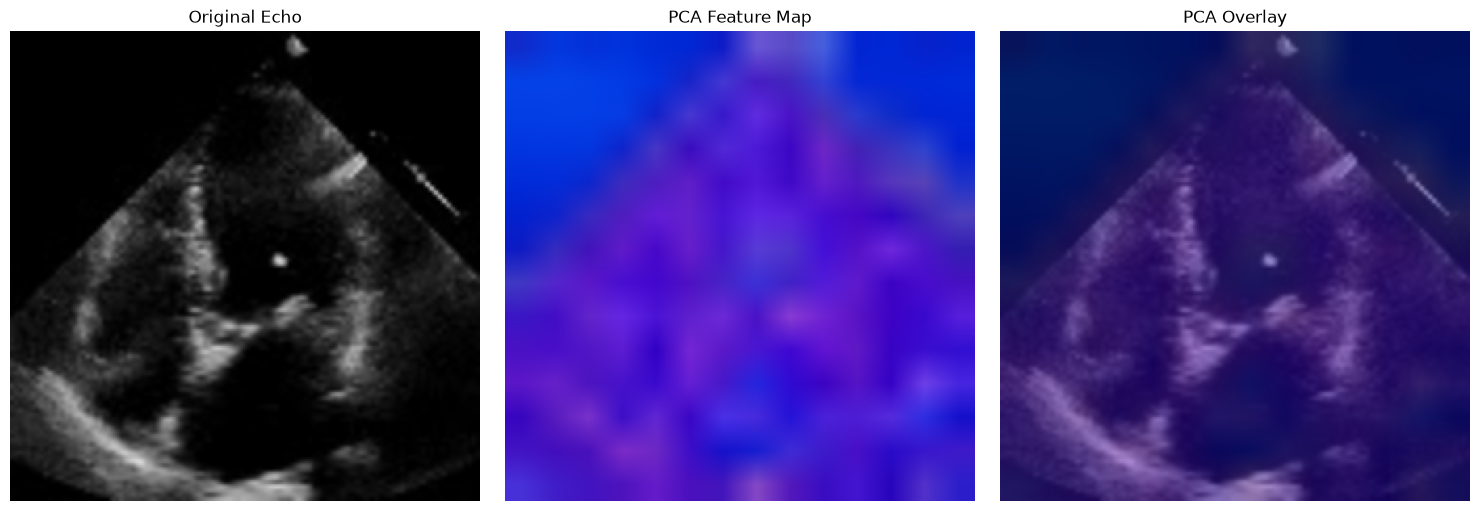

In [24]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)
plt.imshow(Original_Frame)
plt.title("Original Echo")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(PCA_Frame)
plt.title("PCA Feature Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(Overlay_Frame)
plt.title("PCA Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

['d:\\project\\Personal\\Hadi\\EchoJEPA\\output\\pca\\pca_before_finetuning_model.joblib']

In [27]:
PCA_Visualization_Stats_Path = (
    Pca_Dir
    / "pca_before_finetuning_visualization_stats.pt"
)

torch.save(
    {
        "pca_min": torch.from_numpy(
            PCA_Min
        ),
        "pca_max": torch.from_numpy(
            PCA_Max
        )
    },
    PCA_Visualization_Stats_Path
)

print(
    "PCA visualization stats saved:",
    PCA_Visualization_Stats_Path
)


PCA visualization stats saved: d:\project\Personal\Hadi\EchoJEPA\output\pca\pca_before_finetuning_visualization_stats.pt


In [28]:
Overlay_Frames = []

for Frame_Index in range(16):

    Original_Frame = Display_Video[
        Frame_Index
    ]

    PCA_Frame = Upsampled_PCA_Frames[
        Frame_Index
    ]

    Overlay_Frame = (
        (1 - Alpha) * Original_Frame
        +
        Alpha * PCA_Frame
    )

    Overlay_Frame = np.clip(
        Overlay_Frame,
        0.0,
        1.0
    )

    Overlay_Frames.append(
        Overlay_Frame
    )

Overlay_Frames = np.stack(
    Overlay_Frames,
    axis=0
)

print(
    "Overlay Frames Shape:",
    Overlay_Frames.shape
)

Overlay Frames Shape: (16, 224, 224, 3)


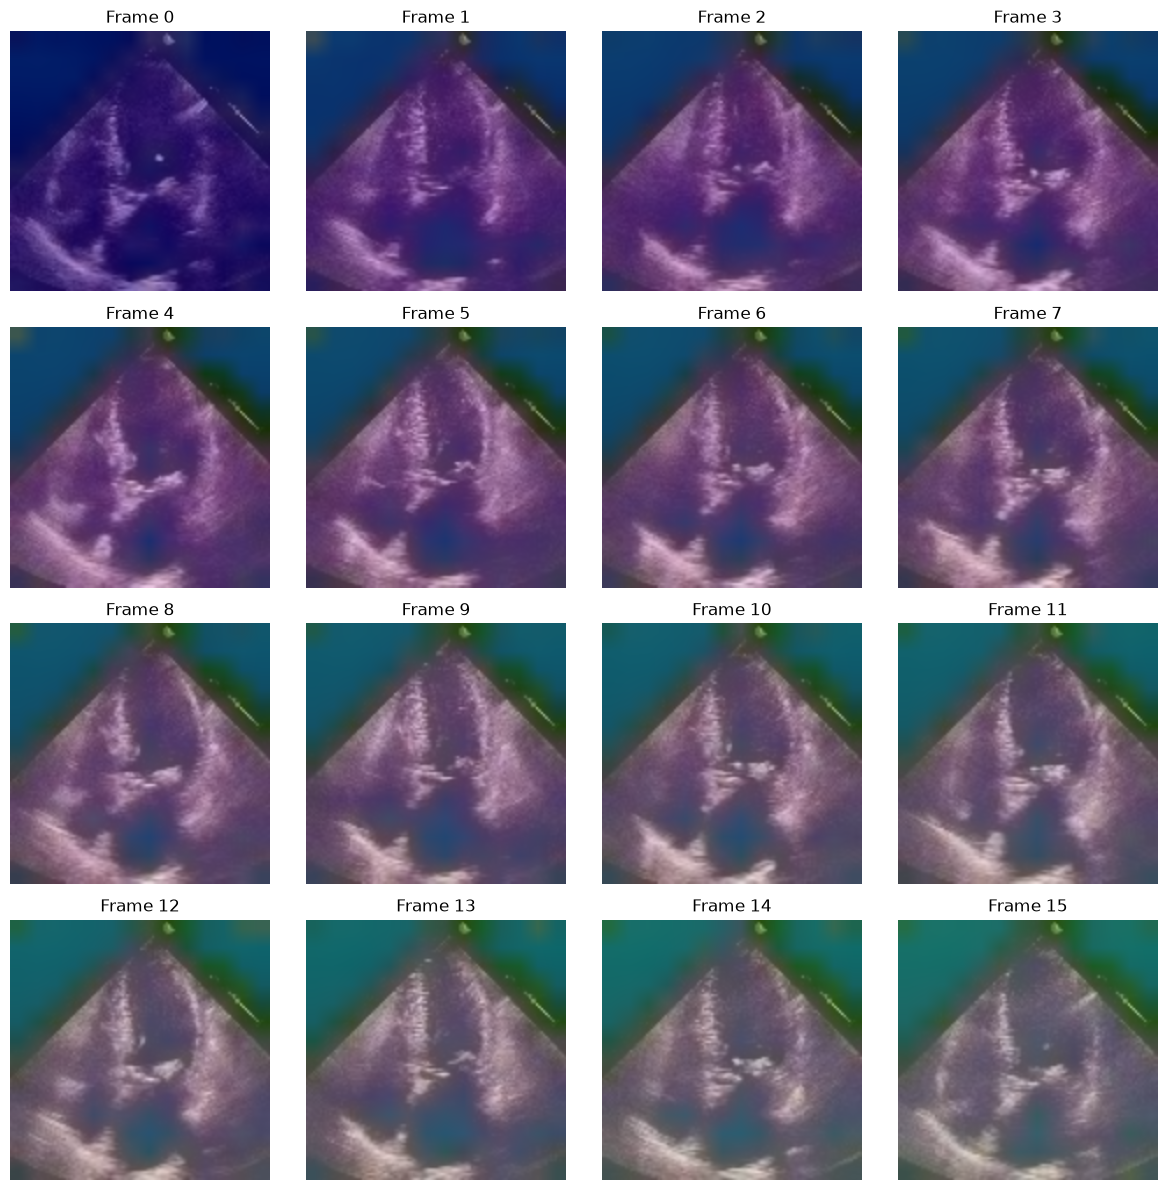

In [29]:
plt.figure(
    figsize=(12, 12)
)

for Frame_Index in range(16):

    plt.subplot(
        4,
        4,
        Frame_Index + 1
    )

    plt.imshow(
        Overlay_Frames[
            Frame_Index
        ]
    )

    plt.title(
        f"Frame {Frame_Index}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

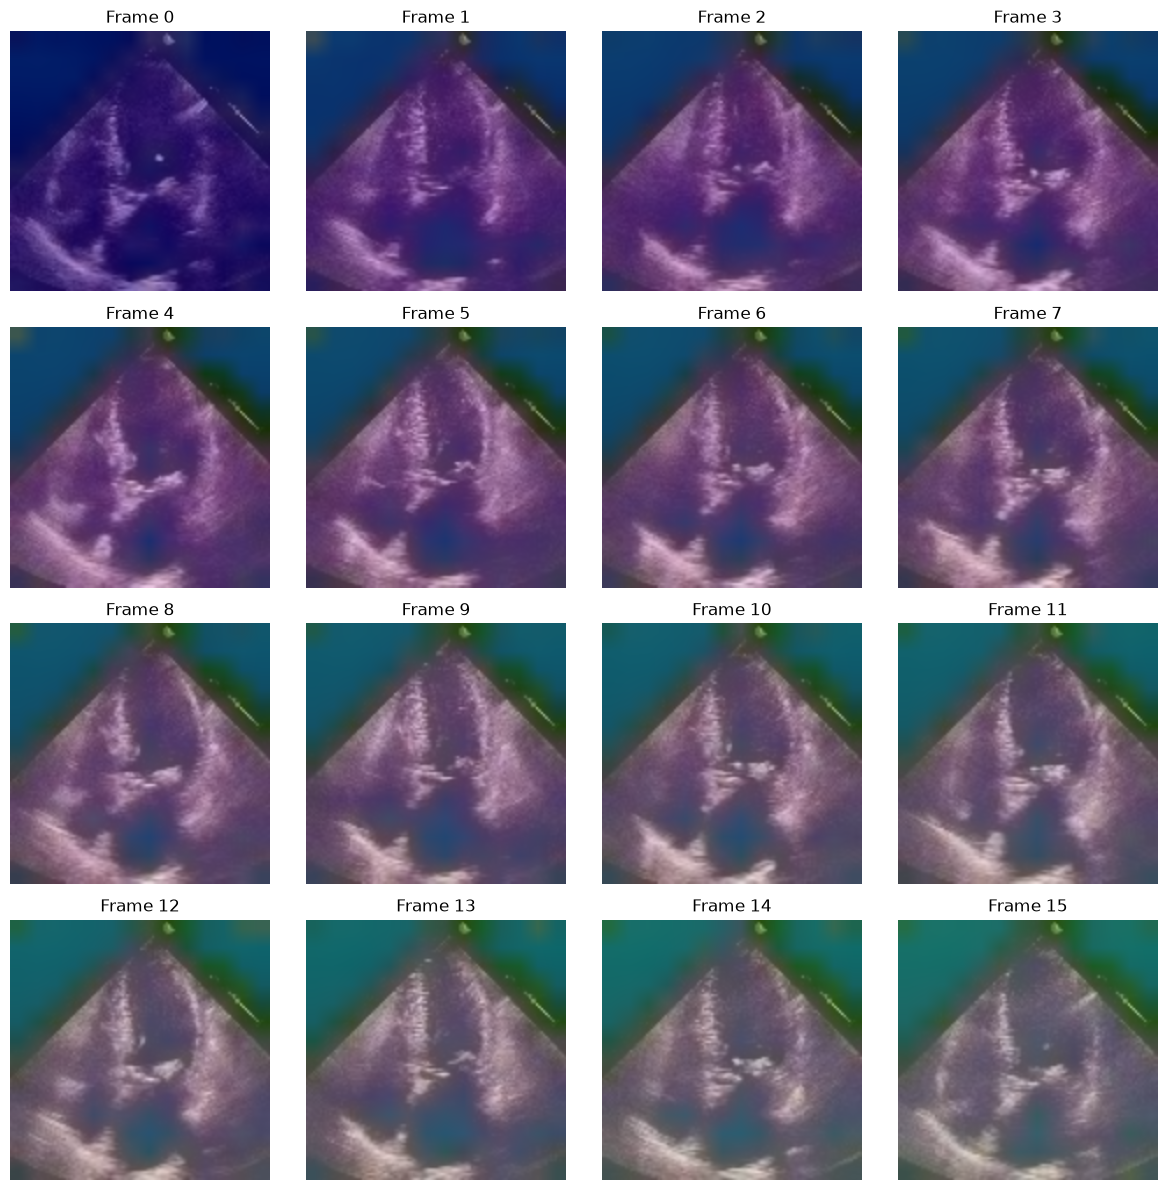

Saved: d:\project\Personal\Hadi\EchoJEPA\output\pca\pca_before_finetuning_overlay.png


In [30]:
Overlay_Figure_Path = (
    Pca_Dir
    / "pca_before_finetuning_overlay.png"
)

plt.figure(
    figsize=(12, 12)
)

for Frame_Index in range(16):

    plt.subplot(
        4,
        4,
        Frame_Index + 1
    )

    plt.imshow(
        Overlay_Frames[
            Frame_Index
        ]
    )

    plt.title(
        f"Frame {Frame_Index}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    Overlay_Figure_Path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    Overlay_Figure_Path
)